This notebook reproduces Fig. 5. We compute the filter functions of the Landau-Zener pulses (see `Fig02-LZ.ipynb`), and the resulting noise susceptibility for $1/f$ noise. Energies are given in units of $x$, times in units of $\hbar/x$, and frequencies in units of $x/\hbar$.

For a noise Hamiltonian $\delta\hat{H}(t)=\sum_j\delta\lambda_j(t)\hat{\sigma}_j$, with $\hat{\sigma}_j$ the Pauli matrices in the fixed (laboratory) basis, the average gate fidelity reads, to second order in the noise strength,
$$
\mathcal{F}_\text{gate}= 1 - \frac{1}{3}\sum_{i}\int_0^\infty df\,S_i(f)F_i(f),
$$
with $S_i(f)$ the spectral density of $\delta\lambda_i$. The filter functions are given by
$$
F_i(f)=\sum_j\left|R_{ij}(f)\right|^2, \qquad R_{ij}(f) = \int_0^{t_\mathrm{f}}dt \operatorname{Tr}[\hat{U}_c^\dagger(t)\hat{\sigma}_i\hat{U}_c(t)\hat{\sigma}_j]\,e^{i2\pi f t},
$$
where $\hat{U}_c(t)$ is the time evolution operator of the noiseless control Hamiltonian. We quantify the sensitivity of a pulse to noise along $\hat{\sigma}_i$ by the noise susceptibility
$$
\chi_i=\int_0^\infty df\,S_i(f)F_i(f),
$$
such that $1-\mathcal{F}_\text{gate}=\sum_i\chi_i/3$. We consider $1/f$ noise, $S_i(f)=A_i/f$, in the frequency window of the grid `omegas`. Since the amplitudes $A_i$ only rescale $\chi_i$, we use the same amplitude for all directions and normalize all curves to the largest value $\chi_\mathrm{max}$ of the $\chi_i$.

The pulses have $n_-=0$ and $n_+\in(-10,10)$, and they are padded with constant tails at $\mp z_0$ before and after the pulse. The total pulse time is $x\,t_\mathrm{f}/\hbar=33\pi/2$.

The first figure shows the filter functions for each direction (not included in the manuscript), and the second figure corresponds to Fig. 5.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from parameterrun import parameterrun
from scipy.integrate import trapezoid

from HQUAD_lib.filter_functions import compute_FF_LZ
from HQUAD_lib.plotting_utils import add_labels, plot_gradient_lines
from HQUAD_lib.QUAD_utils import solve_LZ

In [2]:
x = 1
z0 = 10 * x
tf = np.pi / 2 * 33 / x
tails_factor = 5
omegas = np.logspace(-2, 2, 500)

n_plus = np.linspace(
    -10, 10, 41
)  # Increase for higher resolution (200 values in the manuscript)
n_plus[0] = -np.inf
n_plus[-1] = np.inf
n_minus = 0

alphas = n_plus + n_minus
betas = n_plus - n_minus

In [3]:
def compute_FF(alpha: float, beta: float) -> np.ndarray:
    pulse = solve_LZ(alpha, beta, x=x, z0=-z0)

    # The pulse goes from -z0 to z0, so the constant tails are set at -z0 (before) and z0 (after) the pulse
    boundary_left = np.ones(len(pulse) // tails_factor) * (-z0)
    boundary_right = np.ones(len(pulse) // tails_factor) * z0
    pulse = np.concatenate((boundary_left, pulse, boundary_right))

    return compute_FF_LZ(x, pulse, tf * (1 + 2 / tails_factor), omegas)

In [4]:
FF = np.asarray(parameterrun(compute_FF, [["alpha", "beta"]], [[alphas, betas]]))

compute_FF: [['alpha', 'beta']]:   0%|          | 0/41 [00:00<?, ?it/s]

# Filter functions

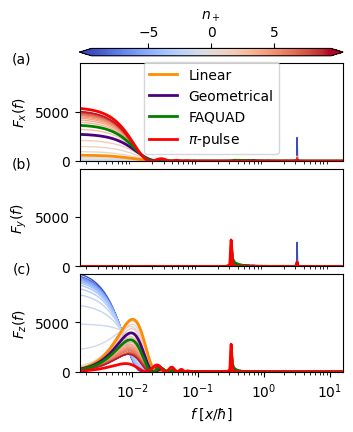

In [5]:
fig, axs = plt.subplots(
    4, figsize=(3.4, 4.2), gridspec_kw={"height_ratios": [0.075, 1, 1, 1]}
)

directions = ["x", "y", "z"]
for i, direction in enumerate(directions):
    ax = axs[i + 1]
    _, sm, _ = plot_gradient_lines(
        omegas / (2 * np.pi),
        FF[:, i],
        alphas,
        betas,
        ax=ax,
        y_label=rf"$F_{direction}(f)$",
        legend_bool=(i == 0),
        cbar_bool=False,
    )

    ax.set_xscale("log")
    ax.set_ylim(0, np.max(FF))

    if i != 2:
        ax.set_xticks([])

axs[1].legend(frameon=True)

plt.colorbar(
    sm,
    cax=axs[0],
    label=r"$n_+ $",
    orientation="horizontal",
    location="top",
    extend="both",
)

axs[-1].set_xlabel(r"$f\; [x / \hbar]$")

fig.subplots_adjust(hspace=0.1)
add_labels(axs[1:], [-0.22, 1.05])

# Noise susceptibility

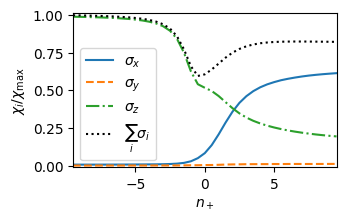

In [6]:
# Since S(f) df = S(omega) d omega for 1/f noise, the integral can be done in omega
S = 1 / omegas
chi = trapezoid(S[None, None, :] * FF, omegas, axis=-1)
chi_max = np.max(chi)

fig, ax = plt.subplots(figsize=(3.4, 2))

labels = [r"$\sigma_x$", r"$\sigma_y$", r"$\sigma_z$"]
styles = ["-", "--", "-."]
for i in range(3):
    ax.plot(n_plus, chi[:, i] / chi_max, label=labels[i], ls=styles[i])

ax.plot(
    n_plus,
    np.sum(chi, axis=1) / chi_max,
    label=r"$\sum_i\sigma_i$",
    color="k",
    ls=":",
)

ax.set_ylabel(r"$\chi_i / \chi_\mathrm{max}$")
ax.legend()

ax.set_xlim(min(n_plus[1:-1]), max(n_plus[1:-1]))
ax.set_ylim(-0.01, 1.01)
ax.set_xlabel(r"$n_+$");